# DOE-038
## POR トレンド

- 対象銘柄: 9984
- 実験計画: 完全実施要因計画 (Full Factorial Design)
- 実験パラメータ
    - なし
- 固定パラメータ
    - TYPE_MA_1: EMA
    - PERIOD_MA_1: 240
        - 短周期移動平均線
    - PERIOD_MA_2: 2400
        - 長周期移動平均線
    - START_TRAILING: 35
        - トレーリング・ストップを開始する最大含み益
    - THRESHOLD_TRAILING: 0.90
        - トレーリング・ストップのしきい値比
    - FOLLOWING_MIN: 14
        - 順方向に設定回数以上更新されていて含み損になればロスカット
    - LOSSCUT_SIMPLE: float = -1e10
        - 単純ロスカット（実質的に無効）
- MA1 / MA2 クロス・シグナルのエントリ・エグジット
    - クロス時に反対売買をしない。
- 評価指標
    - 収益と約定回数

In [1]:
from pathlib import Path

import pandas as pd

# === 実験番号 ===
name_doe = "doe-038"

# pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 300)

# 指定したディレクトリのPathオブジェクトを作成
dir_path = Path(f"../doe/{name_doe}")

# .glob() で .csv ファイルのリスト（イテレータ）を取得してリストに変換
list_csv_file = sorted([str(p) for p in dir_path.glob("*.csv") if p.is_file()])

# 集計対象の条件列
columns_group = [
    "TYPE_MA_1",
    "PERIOD_MA_1",
    "PERIOD_MA_2",
]

# CSV ファイルを読み込んで結合
df = pd.concat(
    [
        pd.read_csv(file).assign(
            DATE=pd.to_datetime(Path(file).stem[:8], format="%Y%m%d")
        )
        for file in list_csv_file
    ],
    ignore_index=True,
)

# 条件ごとに Profit を集計
df_total = df.groupby(columns_group, as_index=False).agg(
    Profit_Total=("Profit", "sum"),
    Profit_Mean=("Profit", "mean"),
    Profit_Median=("Profit", "median"),
    Transactions_Median=("Transactions", "median"),
)

print(df)
print("\nSummary Statistics")
print("\n*** Past", len(list_csv_file), "days statistics ***")
print(df_total)

    TYPE_MA_1  PERIOD_MA_1  PERIOD_MA_2  FLAG_SLOPE  START_TRAILING  THRESHOLD_TRAILING  FOLLOWING_MIN  Profit  Transactions       DATE
0         EMA          240         2400        True              35                 0.9             14    15.0           8.0 2026-04-01
1         EMA          240         2400        True              35                 0.9             14    68.0           6.0 2026-04-02
2         EMA          240         2400        True              35                 0.9             14   -21.0          16.0 2026-04-03
3         EMA          240         2400        True              35                 0.9             14   -48.0           8.0 2026-04-06
4         EMA          240         2400        True              35                 0.9             14   105.0           4.0 2026-04-07
..        ...          ...          ...         ...             ...                 ...            ...     ...           ...        ...
127       EMA          240         2400        T

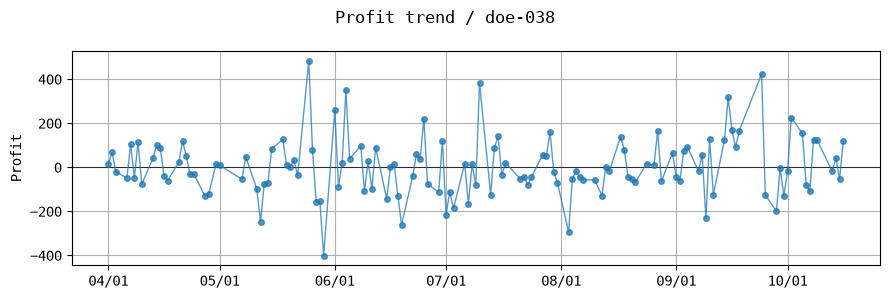

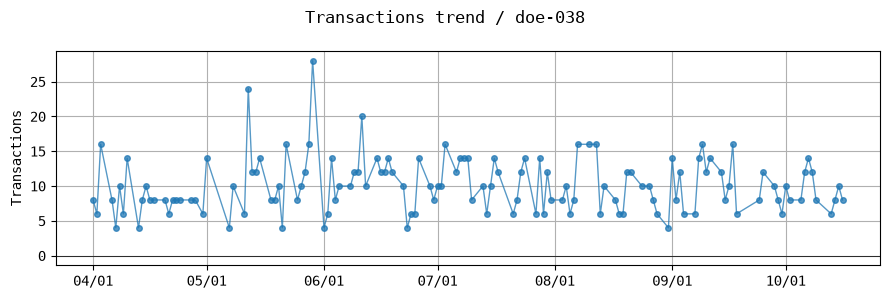

In [2]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "monospace"

for name_y in ["Profit", "Transactions"]:
    fig, ax = plt.subplots(1, 1, figsize=(9, 3))

    # stripplot の x 軸位置（0, 1, 2...）に合わせて線をつなぐ
    x = df["DATE"]
    y = df[name_y]
    ax.plot(
        x,
        y,
        "o-",
        color="C0",
        markersize=4,
        linewidth=1,
        alpha=0.75,
        zorder=5,  # 点の裏に隠れないよう前面に描画
    )
    ax.set(ylabel=name_y)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%d'))
    ax.axhline(y=0, color='black', linewidth=0.75, alpha=0.75)
    ax.grid(True)
    
    fig.suptitle(f"{name_y} trend / {name_doe}")
    
    plt.tight_layout()
    pngfile = f"../doe/{name_doe}/trend_{name_y}.png"
    #plt.savefig(pngfile)
    plt.show()